# Emerging-Issue Status Detection

This notebook implements the simplified PP1 version of Function 2.

## Goal

Detect whether a product aspect shows an emerging negative issue, without yet identifying the exact semantic complaint.

### Output status
- **0** — No meaningful issue
- **1** — Existing issue, but not newly increasing
- **2** — New or rapidly increasing issue

The decision uses:
- normalized negative-review rate
- recent growth in the negative-review rate
- minimum evidence support
- temporal persistence
- EWMA trend evidence
- recent PELT change-point evidence
- uncertainty / confidence

All thresholds are temporary PP1 development values.


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

WORKSPACE = Path.cwd()
if WORKSPACE.name == "notebooks":
    COMPONENT_ROOT = WORKSPACE.parent
elif (WORKSPACE / "data" / "processed").exists():
    COMPONENT_ROOT = WORKSPACE
else:
    COMPONENT_ROOT = WORKSPACE / "component_3"

INPUT = COMPONENT_ROOT / "data" / "processed" / "paq_with_trend_changepoint.csv"

OUTPUT_DIR = COMPONENT_ROOT / "data" / "processed"
TABLE_DIR = COMPONENT_ROOT / "outputs" / "tables"
FIGURE_DIR = COMPONENT_ROOT / "outputs" / "figures"

for p in [OUTPUT_DIR, TABLE_DIR, FIGURE_DIR]:
    p.mkdir(parents=True, exist_ok=True)

OUTPUT = OUTPUT_DIR / "paq_with_emerging_status.csv"

# Temporary PP1 development thresholds
DEV_MIN_SUPPORT = 5
DEV_EXISTING_NEGATIVE_RATE = 0.25
DEV_EMERGING_NEGATIVE_RATE = 0.20
DEV_GROWTH_FROM_PREVIOUS = 0.08
DEV_GROWTH_FROM_HISTORY = 0.10
DEV_PERSISTENCE_QUARTERS = 2
DEV_CHANGEPOINT_WINDOW = 2


## 1. Load the integrated Function 1 output


In [8]:
df = pd.read_csv(INPUT)

required = [
    "parent_asin",
    "aspect",
    "quarter",
    "review_count",
    "negative_rate",
    "trend",
    "latest_change_point",
    "temporal_confidence_dev"
]

missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

df["quarter_period"] = pd.PeriodIndex(df["quarter"], freq="Q")

df = (
    df
    .sort_values(["parent_asin", "aspect", "quarter_period"])
    .reset_index(drop=True)
)

print("Rows:", len(df))
print(
    "Product-aspect series:",
    df[["parent_asin", "aspect"]].drop_duplicates().shape[0]
)
display(df.head())


Rows: 550
Product-aspect series: 50


,parent_asin,aspect,quarter,review_count,mean_sentiment,median_sentiment,positive_rate,neutral_rate,negative_rate,avg_confidence,...,confidence_label_dev,ewma_sentiment,ewma_change,trend_signal,trend,trend_evidence_flag_dev,n_change_points,detected_change_points,latest_change_point,quarter_period
0,B00FFJ0HUE,battery,2021Q1,3,0.1326,-0.1452,0.3333,0.6667,0.0,0.7348,...,Medium,0.0497,NaN,NaN,Stable,Low Support,0,NaN,NaN,2021Q1
1,B00FFJ0HUE,battery,2021Q2,3,-0.0371,-0.0177,0.0000,1.0000,0.0,0.7411,...,Medium,0.0574,0.0077,0.0077,Stable,Low Support,0,NaN,NaN,2021Q2
2,B00FFJ0HUE,battery,2021Q3,5,0.4642,0.4297,0.8000,0.2000,0.0,0.7929,...,Medium,0.1369,0.0794,0.0436,Stable,Adequate,0,NaN,NaN,2021Q3
3,B00FFJ0HUE,battery,2021Q4,5,0.2114,0.1513,0.4000,0.6000,0.0,0.7260,...,Medium,0.1617,0.0249,0.0521,Improving,Adequate,0,NaN,NaN,2021Q4
4,B00FFJ0HUE,battery,2022Q1,2,0.0833,0.0833,0.5000,0.0000,0.5,0.8004,...,Medium,0.1616,-0.0001,0.0124,Stable,Low Support,0,NaN,NaN,2022Q1


## 2. Calculate temporal negative-rate signals

The complaint signal uses a normalized negative-review rate:

`negative aspect reviews / all aspect reviews in that quarter`

This is preferred to raw counts because review volume changes between quarters.


In [9]:
def add_issue_signals(group):
    group = group.copy()

    group["prev_negative_rate"] = group["negative_rate"].shift(1)

    group["negative_rate_growth"] = (
        group["negative_rate"] - group["prev_negative_rate"]
    )

    group["historical_negative_rate"] = (
        group["negative_rate"]
        .expanding()
        .mean()
        .shift(1)
    )

    group["growth_from_history"] = (
        group["negative_rate"] - group["historical_negative_rate"]
    )

    group["above_history"] = (
        group["growth_from_history"] > 0
    ).astype(int)

    group["persistence_2q"] = (
        group["above_history"]
        .rolling(
            window=DEV_PERSISTENCE_QUARTERS,
            min_periods=DEV_PERSISTENCE_QUARTERS
        )
        .sum()
        .eq(DEV_PERSISTENCE_QUARTERS)
    )

    return group

df = pd.concat(
    [
        add_issue_signals(group)
        for _, group in df.groupby(["parent_asin", "aspect"])
    ],
    ignore_index=True
)

display(
    df[[
        "parent_asin",
        "aspect",
        "quarter",
        "review_count",
        "negative_rate",
        "negative_rate_growth",
        "historical_negative_rate",
        "growth_from_history",
        "persistence_2q"
    ]].head(30)
)


,parent_asin,aspect,quarter,review_count,negative_rate,negative_rate_growth,historical_negative_rate,growth_from_history,persistence_2q
0,B00FFJ0HUE,battery,2021Q1,3,0.0,NaN,NaN,NaN,False
1,B00FFJ0HUE,battery,2021Q2,3,0.0,0.0,0.000000,0.000000,False
2,B00FFJ0HUE,battery,2021Q3,5,0.0,0.0,0.000000,0.000000,False
3,B00FFJ0HUE,battery,2021Q4,5,0.0,0.0,0.000000,0.000000,False
4,B00FFJ0HUE,battery,2022Q1,2,0.5,0.5,0.000000,0.500000,False
5,B00FFJ0HUE,battery,2022Q2,6,0.0,-0.5,0.100000,-0.100000,False
6,B00FFJ0HUE,battery,2022Q3,6,0.0,0.0,0.083333,-0.083333,False
7,B00FFJ0HUE,battery,2022Q4,2,0.0,0.0,0.071429,-0.071429,False
8,B00FFJ0HUE,battery,2023Q1,2,0.0,0.0,0.062500,-0.062500,False
9,B00FFJ0HUE,battery,2023Q2,1,0.0,0.0,0.055556,-0.055556,False


## 3. Add recent change-point evidence

A PELT change point is treated as supporting evidence if it occurred in the current quarter or within the previous two quarters.


In [10]:
def quarter_distance(current_q, change_q):
    if pd.isna(change_q) or str(change_q).strip() == "":
        return np.nan

    try:
        current = pd.Period(current_q, freq="Q")
        change = pd.Period(str(change_q), freq="Q")
        return current.ordinal - change.ordinal
    except Exception:
        return np.nan

df["quarters_since_change"] = df.apply(
    lambda row: quarter_distance(
        row["quarter"],
        row["latest_change_point"]
    ),
    axis=1
)

df["recent_change_evidence"] = (
    df["quarters_since_change"]
    .between(0, DEV_CHANGEPOINT_WINDOW, inclusive="both")
)

display(
    df[[
        "parent_asin",
        "aspect",
        "quarter",
        "latest_change_point",
        "quarters_since_change",
        "recent_change_evidence"
    ]].head(30)
)


,parent_asin,aspect,quarter,latest_change_point,quarters_since_change,recent_change_evidence
0,B00FFJ0HUE,battery,2021Q1,NaN,NaN,False
1,B00FFJ0HUE,battery,2021Q2,NaN,NaN,False
2,B00FFJ0HUE,battery,2021Q3,NaN,NaN,False
3,B00FFJ0HUE,battery,2021Q4,NaN,NaN,False
4,B00FFJ0HUE,battery,2022Q1,NaN,NaN,False
5,B00FFJ0HUE,battery,2022Q2,NaN,NaN,False
6,B00FFJ0HUE,battery,2022Q3,NaN,NaN,False
7,B00FFJ0HUE,battery,2022Q4,NaN,NaN,False
8,B00FFJ0HUE,battery,2023Q1,NaN,NaN,False
9,B00FFJ0HUE,battery,2023Q2,NaN,NaN,False


## 4. Classify emerging-issue status

### Status 2
Enough support + meaningful negative rate + strong growth + supporting temporal evidence.

### Status 1
Negative rate is high, but it does not satisfy the new/rapid-growth rule.

### Status 0
No strong issue signal.


In [11]:
def classify_emerging_status(row):
    enough_support = row["review_count"] >= DEV_MIN_SUPPORT
    current_issue = row["negative_rate"] >= DEV_EMERGING_NEGATIVE_RATE

    strong_growth = (
        (
            pd.notna(row["negative_rate_growth"])
            and row["negative_rate_growth"] >= DEV_GROWTH_FROM_PREVIOUS
        )
        or
        (
            pd.notna(row["growth_from_history"])
            and row["growth_from_history"] >= DEV_GROWTH_FROM_HISTORY
        )
    )

    supporting_temporal_evidence = (
        bool(row["persistence_2q"])
        or row["trend"] == "Declining"
        or bool(row["recent_change_evidence"])
    )

    if (
        enough_support
        and current_issue
        and strong_growth
        and supporting_temporal_evidence
    ):
        return 2

    if (
        enough_support
        and row["negative_rate"] >= DEV_EXISTING_NEGATIVE_RATE
    ):
        return 1

    return 0

df["emerging_status"] = df.apply(
    classify_emerging_status,
    axis=1
)

df["emerging_label"] = df["emerging_status"].map({
    0: "No meaningful issue",
    1: "Existing issue",
    2: "New / rapidly increasing issue"
})

display(
    df[[
        "parent_asin",
        "aspect",
        "quarter",
        "negative_rate",
        "negative_rate_growth",
        "growth_from_history",
        "persistence_2q",
        "trend",
        "recent_change_evidence",
        "emerging_status",
        "emerging_label"
    ]].head(40)
)


,parent_asin,aspect,quarter,negative_rate,negative_rate_growth,growth_from_history,persistence_2q,trend,recent_change_evidence,emerging_status,emerging_label
0,B00FFJ0HUE,battery,2021Q1,0.0,NaN,NaN,False,Stable,False,0,No meaningful issue
1,B00FFJ0HUE,battery,2021Q2,0.0,0.0,0.000000,False,Stable,False,0,No meaningful issue
2,B00FFJ0HUE,battery,2021Q3,0.0,0.0,0.000000,False,Stable,False,0,No meaningful issue
3,B00FFJ0HUE,battery,2021Q4,0.0,0.0,0.000000,False,Improving,False,0,No meaningful issue
4,B00FFJ0HUE,battery,2022Q1,0.5,0.5,0.500000,False,Stable,False,0,No meaningful issue
5,B00FFJ0HUE,battery,2022Q2,0.0,-0.5,-0.100000,False,Stable,False,0,No meaningful issue
6,B00FFJ0HUE,battery,2022Q3,0.0,0.0,-0.083333,False,Improving,False,0,No meaningful issue
7,B00FFJ0HUE,battery,2022Q4,0.0,0.0,-0.071429,False,Stable,False,0,No meaningful issue
8,B00FFJ0HUE,battery,2023Q1,0.0,0.0,-0.062500,False,Stable,False,0,No meaningful issue
9,B00FFJ0HUE,battery,2023Q2,0.0,0.0,-0.055556,False,Stable,False,0,No meaningful issue


## 5. Issue risk

Development rule:
- **High** — emerging issue plus Declining trend or recent structural change
- **Medium** — emerging issue without extra evidence, or an existing issue
- **Low** — no meaningful issue


In [12]:
def classify_issue_risk(row):
    if row["emerging_status"] == 2:
        if (
            row["trend"] == "Declining"
            or bool(row["recent_change_evidence"])
        ):
            return "High"
        return "Medium"

    if row["emerging_status"] == 1:
        return "Medium"

    return "Low"

df["issue_risk"] = df.apply(
    classify_issue_risk,
    axis=1
)


## 6. Issue confidence

The development confidence score combines:
- temporal confidence from the smoothing stage
- review support
- persistence evidence


In [13]:
support_factor = (
    df["review_count"]
    / (df["review_count"] + DEV_MIN_SUPPORT)
)

persistence_factor = df["persistence_2q"].astype(float)

df["issue_confidence_dev"] = (
    0.65 * df["temporal_confidence_dev"]
    + 0.25 * support_factor
    + 0.10 * persistence_factor
).clip(0, 1)

def confidence_label(value):
    if value >= 0.80:
        return "High"
    if value >= 0.60:
        return "Medium"
    return "Low"

df["issue_confidence_label_dev"] = (
    df["issue_confidence_dev"].apply(confidence_label)
)

display(
    df[[
        "parent_asin",
        "aspect",
        "quarter",
        "emerging_status",
        "issue_risk",
        "issue_confidence_dev",
        "issue_confidence_label_dev"
    ]].head(30)
)


,parent_asin,aspect,quarter,emerging_status,issue_risk,issue_confidence_dev,issue_confidence_label_dev
0,B00FFJ0HUE,battery,2021Q1,0,Low,0.496490,Low
1,B00FFJ0HUE,battery,2021Q2,0,Low,0.520605,Low
2,B00FFJ0HUE,battery,2021Q3,0,Low,0.582730,Low
3,B00FFJ0HUE,battery,2021Q4,0,Low,0.576945,Low
4,B00FFJ0HUE,battery,2022Q1,0,Low,0.468384,Low
5,B00FFJ0HUE,battery,2022Q2,0,Low,0.594224,Low
6,B00FFJ0HUE,battery,2022Q3,0,Low,0.600594,Medium
7,B00FFJ0HUE,battery,2022Q4,0,Low,0.477549,Low
8,B00FFJ0HUE,battery,2023Q1,0,Low,0.492889,Low
9,B00FFJ0HUE,battery,2023Q2,0,Low,0.428027,Low


## 7. Latest emerging-issue status for each Product × Aspect


In [14]:
latest = (
    df
    .sort_values("quarter_period")
    .groupby(["parent_asin", "aspect"], as_index=False)
    .tail(1)
    .copy()
)

latest_issue_table = latest[[
    "parent_asin",
    "aspect",
    "quarter",
    "negative_rate",
    "negative_rate_growth",
    "growth_from_history",
    "trend",
    "latest_change_point",
    "emerging_status",
    "emerging_label",
    "issue_risk",
    "issue_confidence_dev",
    "issue_confidence_label_dev"
]].copy()

latest_issue_table.to_csv(
    TABLE_DIR / "latest_emerging_issue_status.csv",
    index=False
)

display(
    latest_issue_table.sort_values(
        ["emerging_status", "issue_confidence_dev"],
        ascending=[False, False]
    )
)


,parent_asin,aspect,quarter,negative_rate,negative_rate_growth,growth_from_history,trend,latest_change_point,emerging_status,emerging_label,issue_risk,issue_confidence_dev,issue_confidence_label_dev
395,B01MPXRXR0,battery,2023Q3,0.8333,0.5833,0.70319,Declining,2022Q4,2,New / rapidly increasing issue,High,0.786981,Medium
329,B019BX7F86,thermal,2023Q3,0.5455,0.1011,0.44948,Declining,2023Q1,2,New / rapidly increasing issue,High,0.771335,Medium
153,B00L49X8E6,performance,2023Q3,0.3636,0.2207,0.34098,Stable,NaN,2,New / rapidly increasing issue,Medium,0.763860,Medium
384,B01K1IO3QW,thermal,2023Q3,1.0000,0.4286,0.75861,Declining,2022Q4,2,New / rapidly increasing issue,High,0.763164,Medium
263,B00TW47DSW,performance,2023Q3,0.3750,0.3750,0.32738,Stable,NaN,1,Existing issue,Medium,0.627761,Medium
351,B01K1IO3QW,display,2023Q3,0.0909,0.0140,0.01667,Stable,NaN,0,No meaningful issue,Low,0.774845,Medium
340,B01K1IO3QW,battery,2023Q3,0.1818,-0.0682,0.10574,Stable,NaN,0,No meaningful issue,Low,0.765485,Medium
318,B019BX7F86,performance,2023Q3,0.1000,-0.0111,0.07342,Stable,NaN,0,No meaningful issue,Low,0.759627,Medium
241,B00TW47DSW,camera,2023Q3,0.1250,-0.0179,0.02463,Stable,NaN,0,No meaningful issue,Low,0.727306,Medium
197,B00NOSVK54,display,2023Q3,0.0000,0.0000,-0.06715,Stable,2022Q2,0,No meaningful issue,Low,0.721436,Medium


## 8. Status distribution


,emerging_label,count
0,No meaningful issue,45
1,New / rapidly increasing issue,4
2,Existing issue,1


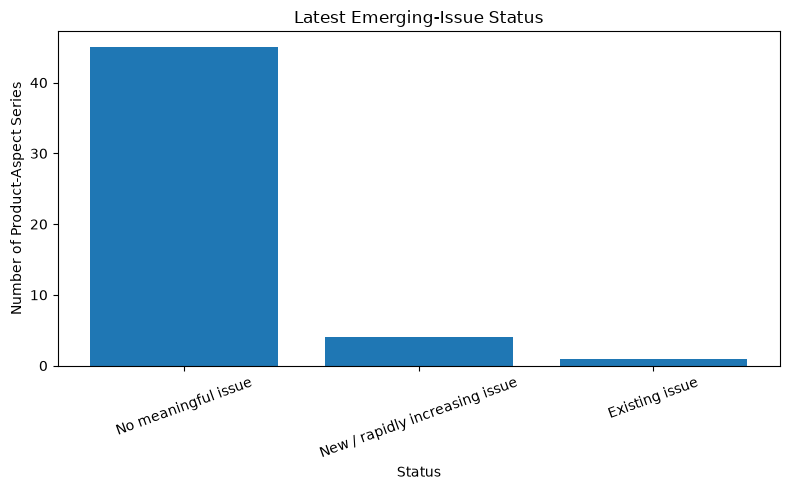

In [15]:
status_counts = latest_issue_table["emerging_label"].value_counts()

display(
    status_counts
    .rename("count")
    .reset_index()
)

plt.figure(figsize=(8, 5))
plt.bar(
    status_counts.index,
    status_counts.values
)

plt.title("Latest Emerging-Issue Status")
plt.xlabel("Status")
plt.ylabel("Number of Product-Aspect Series")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "emerging_issue_status_distribution.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


## 9. Plot one strongest emerging case


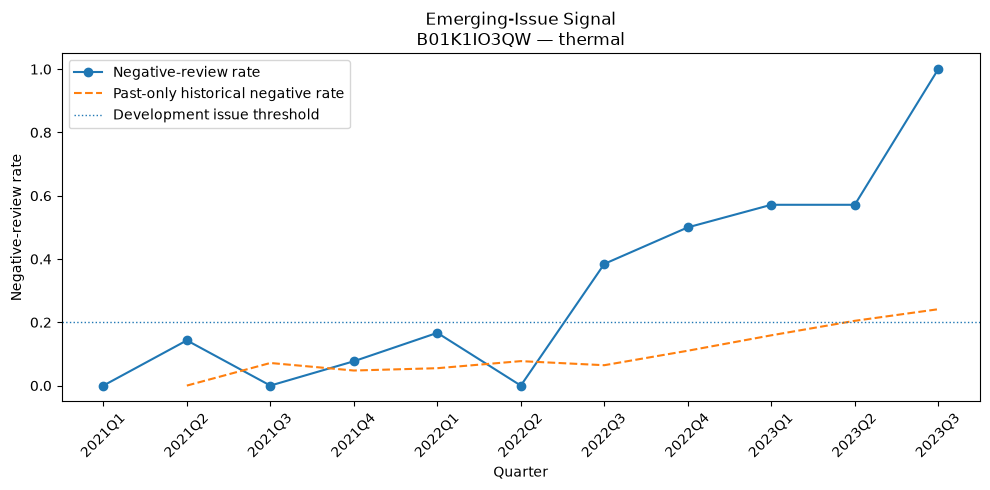

Example product: B01K1IO3QW
Example aspect: thermal
Latest status: New / rapidly increasing issue
Risk: High
Confidence: 0.7632


In [16]:
ranked = latest_issue_table.copy()

ranked["selection_score"] = (
    ranked["emerging_status"] * 10
    + ranked["negative_rate"].fillna(0)
    + ranked["growth_from_history"].fillna(0)
)

example_row = (
    ranked
    .sort_values("selection_score", ascending=False)
    .iloc[0]
)

example_product = example_row["parent_asin"]
example_aspect = example_row["aspect"]

example = df[
    (df["parent_asin"] == example_product)
    & (df["aspect"] == example_aspect)
].copy()

example = example.sort_values("quarter_period")

plt.figure(figsize=(10, 5))

plt.plot(
    example["quarter"],
    example["negative_rate"],
    marker="o",
    label="Negative-review rate"
)

plt.plot(
    example["quarter"],
    example["historical_negative_rate"],
    linestyle="--",
    label="Past-only historical negative rate"
)

plt.axhline(
    DEV_EMERGING_NEGATIVE_RATE,
    linestyle=":",
    linewidth=1,
    label="Development issue threshold"
)

plt.title(
    f"Emerging-Issue Signal\n"
    f"{example_product} — {example_aspect}"
)

plt.xlabel("Quarter")
plt.ylabel("Negative-review rate")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "emerging_issue_example.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("Example product:", example_product)
print("Example aspect:", example_aspect)
print("Latest status:", example_row["emerging_label"])
print("Risk:", example_row["issue_risk"])
print("Confidence:", round(example_row["issue_confidence_dev"], 4))


## 10. Save the integrated PP1 output


In [17]:
df = df.drop(columns=["quarter_period"])

numeric_columns = [
    "prev_negative_rate",
    "negative_rate_growth",
    "historical_negative_rate",
    "growth_from_history",
    "quarters_since_change",
    "issue_confidence_dev"
]

for c in numeric_columns:
    if c in df.columns:
        df[c] = df[c].round(4)

df.to_csv(
    OUTPUT,
    index=False
)

print("Saved:", OUTPUT)
print("Rows:", len(df))


Saved: c:\Users\victus\Desktop\Repository\J26-DS-349\component_3\data\processed\paq_with_emerging_status.csv
Rows: 550
